# Advanced Custom CNN

Phân loại ảnh thành 4 lớp: fire, nofire, smoke và smokefire bằng CNN tự thiết kế (Residual + Squeeze-and-Excitation), train từ đầu.

1. Import thư viện và cấu hình
2. Nạp dữ liệu và xử lý ảnh
3. Xây dựng model
4. Huấn luyện
5. Đánh giá trên tập test
6. Lưu kết quả

## Bước 1 – Import thư viện và cấu hình

Đặt kích thước ảnh, batch size, số epoch và đường dẫn lưu kết quả. Seed 42 giúp hạn chế khác biệt giữa các lần chạy.

`USE_CHECKPOINTS = True`: lần chạy nào đã có checkpoint trong `models/` thì nạp lại và bỏ qua bước train; đặt `False` để luôn train lại.

In [1]:
from pathlib import Path
import json
import tensorflow as tf
from tensorflow.keras import layers, callbacks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

ROOT = Path.cwd() if (Path.cwd() / 'notebooks').exists() else Path.cwd().parent
CLASS_NAMES = ['fire', 'nofire', 'smoke', 'smokefire']
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 50
SEED = 42
USE_CHECKPOINTS = True  # dùng lại checkpoint trong models/ nếu đã có; False: luôn train lại
RESULT_DIR = ROOT / 'results/custom_cnn_transfer_preprocessing'
MODEL_PATH = ROOT / 'models/custom_cnn_transfer_preprocessing.keras'
RESULT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH.parent.mkdir(exist_ok=True)

tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

I0000 00:00:1791793926.358651  523081 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791793926.548518  523081 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791793927.975617  523081 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | GPU: []


W0000 00:00:1791793929.728805  523081 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## Bước 2 – Nạp dữ liệu và xử lý ảnh

Đọc `data/split.csv`chứa đường dẫn tới 4800 ảnh đã resize 224x224, lấy các ảnh có trạng thái `ok` và kiểm tra nhãn khớp với class index.


In [2]:
df = pd.read_csv(ROOT / 'data/split.csv')
df = df[df['status'] == 'ok'].copy()
assert (df['label'].map({name: i for i, name in enumerate(CLASS_NAMES)}) == df['class_index']).all()
assert set(df['split']) == {'train', 'val', 'test'}
display(pd.crosstab(df['split'], df['label'])[CLASS_NAMES])

label,fire,nofire,smoke,smokefire
split,,,,
test,200,200,200,200
train,800,800,800,800
val,200,200,200,200


In [3]:
def load_image(filepath, label):
    image = tf.io.decode_jpeg(tf.io.read_file(filepath), channels=3)
    image = tf.ensure_shape(image, [224, 224, 3])
    return tf.cast(image, tf.float32) / 255.0, tf.one_hot(label, len(CLASS_NAMES))


def make_dataset(split, shuffle=False):
    part = df[df['split'] == split].reset_index(drop=True)
    paths = [str(ROOT / p) for p in part['processed_filepath']]
    assert paths and all(Path(p).is_file() for p in paths), 'Thiếu ảnh processed.'
    ds = tf.data.Dataset.from_tensor_slices((paths, part['class_index'].astype('int32')))
    if shuffle:
        ds = ds.shuffle(len(part), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset('train', shuffle=True)
val_ds = make_dataset('val')
test_ds = make_dataset('test')
test_df = df[df['split'] == 'test'].reset_index(drop=True)

## Bước 3 – Xây dựng model
CNN chỉ xếp Conv2D liên tiếp thì khó học khi mạng sâu (gradient biến mất) và không biết kênh nào quan trọng. Nên mình dùng:
- **Residual (đường tắt)**: cộng input vào output để gradient đi thẳng được.
- **SE block**: mạng tự học trọng số cho từng kênh (lửa là kênh cam/đỏ, khói là vùng mờ).
- **Global Average Pooling**: thay Flatten để ít tham số hơn, đỡ overfit.

Stem Conv 3×3 stride 2 → 5 khối Residual–SE (64, 128, 128, 256, 256 kênh; khối đầu của tầng 128 và 256 dùng stride 2) → Global Average Pooling → Dropout(0,4) → Dense(128, swish) → Dense(4, Softmax).



In [4]:
def se_block(x, ratio=16):
    channels = x.shape[-1]
    s = layers.GlobalAveragePooling2D()(x)
    s = layers.Dense(channels // ratio, activation='relu', use_bias=False)(s)
    s = layers.Dense(channels, activation='sigmoid', use_bias=False)(s)
    return layers.Multiply()([x, layers.Reshape((1, 1, channels))(s)])


def residual_se_block(x, filters, stride=1):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('swish')(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = se_block(x)
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same', use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    return layers.Activation('swish')(layers.Add()([x, shortcut]))


inputs = layers.Input(shape=(*IMAGE_SIZE, 3), name='input')
x = layers.Conv2D(32, 3, strides=2, padding='same', use_bias=False)(inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation('swish')(x)          # 112x112x32
x = residual_se_block(x, 64)               # 112x112x64
x = residual_se_block(x, 128, stride=2)    # 56x56x128
x = residual_se_block(x, 128)
x = residual_se_block(x, 256, stride=2)    # 28x28x256
x = residual_se_block(x, 256)
x = layers.GlobalAveragePooling2D(name='gap')(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='swish')(x)
outputs = layers.Dense(len(CLASS_NAMES), activation='softmax', name='output')(x)

model = tf.keras.Model(inputs, outputs, name='Advanced_Custom_CNN')
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05), metrics=['accuracy'])
model.summary()

Model: "Advanced_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        864 │ input[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,432 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     36,864 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │        256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │        256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 64)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      2,048 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ multiply[0][0],   │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 112, 112,  │          0 │ add[0][0]       

 Total params: 2,742,628 (10.46 MB)

 Trainable params: 2,738,340 (10.45 MB)

 Non-trainable params: 4,288 (16.75 KB)

## Bước 4 – Huấn luyện

Train tối đa 50 epoch, theo dõi validation loss:

- Lưu model có validation loss thấp nhất.
- Giảm learning rate một nửa sau 4 epoch không cải thiện, tối thiểu 0,000001.
- Dừng sau 12 epoch không cải thiện.

Biểu đồ accuracy và loss dùng để theo dõi quá trình học. Với `USE_CHECKPOINTS = True`, lần chạy nào đã có checkpoint trong `models/` thì bỏ qua bước train; biểu đồ và metrics đọc lịch sử train từ `results/`.

In [5]:
if USE_CHECKPOINTS and MODEL_PATH.exists():
    print('Dùng checkpoint có sẵn, bỏ qua bước train:', MODEL_PATH.name)
else:
    training_callbacks = [
        callbacks.ModelCheckpoint(MODEL_PATH, monitor='val_loss', save_best_only=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
        callbacks.EarlyStopping(monitor='val_loss', patience=12),
        callbacks.CSVLogger(RESULT_DIR / 'training_history.csv'),
    ]
    model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
              callbacks=training_callbacks, verbose=2)

Dùng checkpoint có sẵn, bỏ qua bước train: custom_cnn_transfer_preprocessing.keras


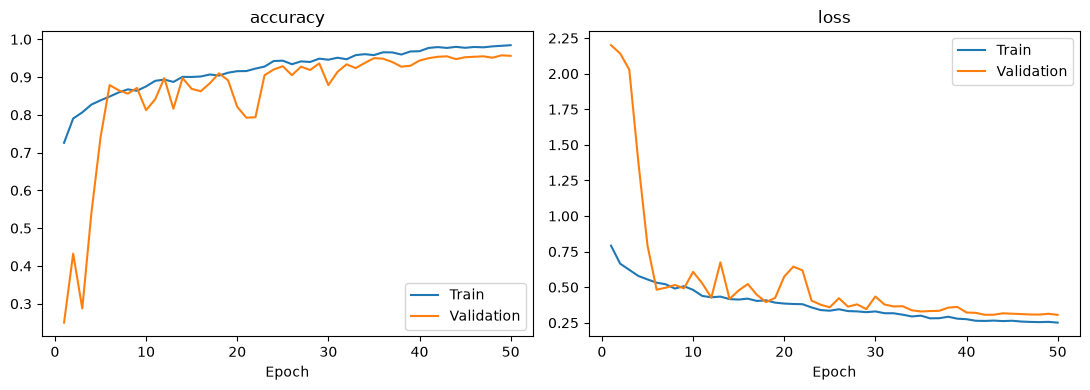

In [6]:
history = pd.read_csv(RESULT_DIR / 'training_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ['accuracy', 'loss']):
    ax.plot(history['epoch'] + 1, history[metric], label='Train')
    ax.plot(history['epoch'] + 1, history['val_' + metric], label='Validation')
    ax.set(xlabel='Epoch', title=metric)
    ax.legend()
plt.tight_layout()
plt.savefig(RESULT_DIR / 'accuracy_loss_curves.png', dpi=150)
plt.show()

## Bước 5 – Đánh giá trên tập test


,precision,recall,f1-score,support
fire,0.9766,0.6250,0.7622,200.0000
nofire,0.9648,0.9600,0.9624,200.0000
smoke,0.7807,0.7300,0.7545,200.0000
smokefire,0.5699,0.8150,0.6708,200.0000
accuracy,0.7825,0.7825,0.7825,0.7825
macro avg,0.8230,0.7825,0.7875,800.0000
weighted avg,0.8230,0.7825,0.7875,800.0000


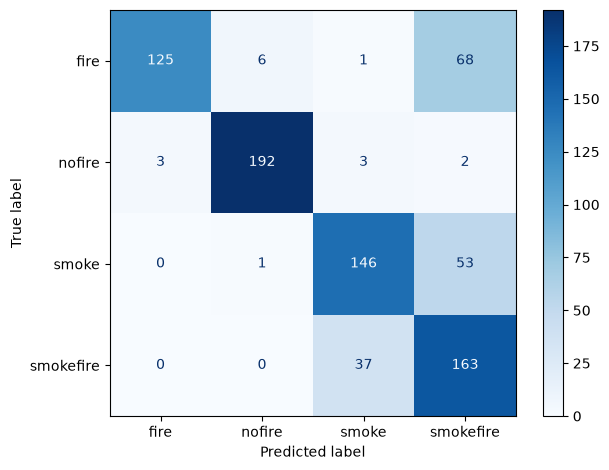

Accuracy: 78.25% | Macro F1: 0.7875
smokefire → smoke: 37 | smoke → smokefire: 53


In [7]:
best_model = tf.keras.models.load_model(MODEL_PATH)
loss, accuracy = best_model.evaluate(test_ds, verbose=0)
probabilities = best_model.predict(test_ds, verbose=0)
y_true = test_df['class_index'].to_numpy()
y_pred = probabilities.argmax(axis=1)
assert np.isclose(accuracy, (y_true == y_pred).mean())

report = classification_report(y_true, y_pred, labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0)
matrix = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))
display(pd.DataFrame(report).T.round(4))

ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(cmap='Blues')
plt.tight_layout()
plt.savefig(RESULT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()
print(f'Accuracy: {accuracy:.2%} | Macro F1: {report["macro avg"]["f1-score"]:.4f}')
print('smokefire → smoke:', matrix[3, 2], '| smoke → smokefire:', matrix[2, 3])

## Bước 6 – Lưu kết quả

Lưu metrics, dự đoán từng ảnh, danh sách ảnh sai và confusion matrix tại `results/custom_cnn_transfer_preprocessing/`. Checkpoint được lưu tại `models/custom_cnn_transfer_preprocessing.keras`.

In [8]:
predictions = test_df[['filepath', 'processed_filepath', 'label', 'class_index']].copy()
predictions['predicted_label'] = np.array(CLASS_NAMES)[y_pred]
predictions['confidence'] = probabilities.max(axis=1)
predictions.to_csv(RESULT_DIR / 'predictions.csv', index=False)
predictions[y_true != y_pred].to_csv(RESULT_DIR / 'misclassified.csv', index=False)
pd.DataFrame(report).T.to_csv(RESULT_DIR / 'classification_report.csv', index_label='class')
pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    RESULT_DIR / 'confusion_matrix.csv', index_label='true_label')

metrics = {
    'test_accuracy': float(accuracy), 'test_loss': float(loss),
    'macro_f1': report['macro avg']['f1-score'],
    'misclassified_count': int((y_true != y_pred).sum()),
    'parameter_count': best_model.count_params(),
    'best_epoch': int(history['val_loss'].argmin()) + 1,
    'best_val_loss': float(history['val_loss'].min()),
    'class_names': CLASS_NAMES, 'image_size': list(IMAGE_SIZE), 'seed': SEED,
    'preprocessing': {'source': 'processed_filepath', 'manifest': 'data/split.csv',
        'normalization': 'pixel / 255', 'augmentation': 'none'},
    'training_config': {'residual_se_blocks': [64, 128, 128, 256, 256], 'activation': 'swish',
        'dropout': 0.4, 'dense_units': 128, 'label_smoothing': 0.05, 'optimizer': 'Adam',
        'learning_rate': 1e-3, 'batch_size': BATCH_SIZE, 'epochs': EPOCHS, 'early_stopping_patience': 12},
    'tensorflow_version': tf.__version__,
}
(RESULT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
MODEL_PATH.with_suffix('.labels.json').write_text(json.dumps(CLASS_NAMES), encoding='utf-8')

40